# 05 · Content and collaborative models

Every model has one method, `score(seed_matrix) -> playlists x tracks`, so the same evaluation code
ranks them all. All tuning in this notebook uses the **validation** split; the test split is kept
for notebook 07.

Metrics (`src/evaluation/metrics.py`):
* **Recall@K** - share of a playlist's held-out tracks found in the top K (capped by K);
* **NDCG@K** - like recall but rewards hits near the top;
* **HitRate@K** - share of playlists with at least one hit;
* **coverage@10** - share of the catalog that appears in anyone's top 10 (popularity bias check);
* **diversity@10** - 1 − mean pairwise content similarity inside a top 10.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
import time
from sklearn.preprocessing import StandardScaler
from src.data.load import load_catalog
from src import artifacts
from src.features.interaction_matrix import load_splits, short_playlists
from src.features.content_embeddings import combine
from src.evaluation.metrics import evaluate, compare
from src.models.baselines import PopularityRecommender, RandomRecommender
from src.models.content import ContentRecommender
from src.models.collaborative import ItemKNN, ALSRecommender, BPRRecommender

tracks = load_catalog()
feats = artifacts.load_features()
splits = load_splits()
train, val = splits["train"], splits["val"]
blocks = {"audio": feats["audio"], "genre": feats["genre"], "text": feats["text"]}

rng = np.random.default_rng(0)
val_users = rng.choice(np.where(np.diff(val.indptr) > 0)[0], 2000, replace=False)
def val_score(model, **kw):
    return evaluate(model, train, val, users=val_users, ks=(10, 20), **kw)

## 1. Content model: does the feature engineering pay off?

An ablation: the same content recommender (cosine to the playlist's mean vector) on different
feature sets, scored on validation playlists.

In [2]:
raw_audio = StandardScaler().fit_transform(tracks[config.AUDIO_FEATURES])
variants = {
    "text only (original approach)": blocks["text"],
    "raw audio (9 features, standardised)": raw_audio,
    "engineered audio": blocks["audio"],
    "genre embedding": blocks["genre"],
    "engineered audio + genre": combine(blocks, {"audio": 1, "genre": 1, "text": 0}),
    "audio + genre + text": combine(blocks, {"audio": 1, "genre": 1, "text": 0.35}),
}
abl = {name: val_score(ContentRecommender(E)) for name, E in variants.items()}
abl_df = compare(abl)[["recall@10", "recall@20", "ndcg@10", "hit@10"]]
abl_df

,recall@10,recall@20,ndcg@10,hit@10
text only (original approach),0.0116,0.0191,0.0079,0.0350
"raw audio (9 features, standardised)",0.0076,0.0129,0.0047,0.0235
engineered audio,0.0085,0.0167,0.0054,0.0300
genre embedding,0.0237,0.0468,0.0167,0.0845
engineered audio + genre,0.0280,0.0503,0.0189,0.0945
audio + genre + text,0.0255,0.0528,0.0174,0.0855


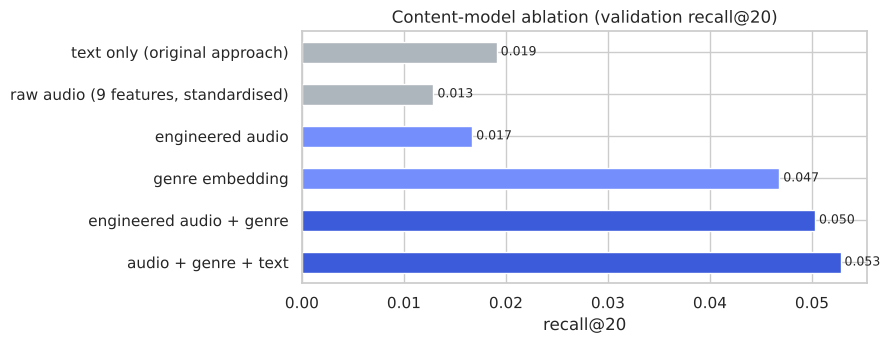

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
abl_df["recall@20"].plot.barh(ax=ax, color=["#adb5bd", "#adb5bd", "#748ffc", "#748ffc", "#3b5bdb", "#3b5bdb"])
ax.invert_yaxis(); ax.set(title="Content-model ablation (validation recall@20)", xlabel="recall@20")
for i, v in enumerate(abl_df["recall@20"]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "05_content_ablation.png"); plt.show()

Three things stand out:

* **Engineered audio beats raw audio by about 30%** (recall@20 0.017 vs 0.013): folding tempo,
  the quantile transform and the weights all help.
* **Audio alone is still weak here**, weaker than text. Notebook 01 showed why: many genres overlap in
  audio space, and these simulated listeners pick a scene first. Text does well mostly because of
  the artist tokens, which match the artist loyalty in the listening data.
* **Engineered audio + the learned genre map is about 2.6x the original text-only approach**, and
  adding a little text helps a bit more.

### Tune the block weights

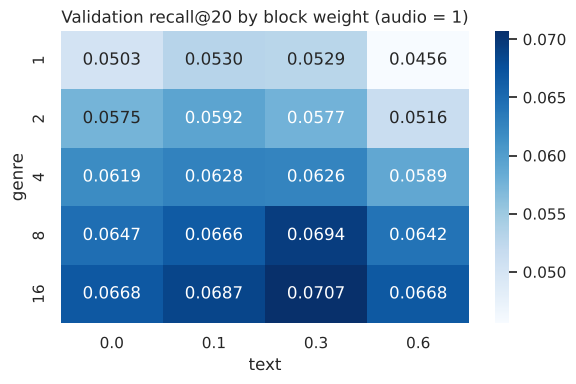

best block weights: {'audio': 1.0, 'genre': 16.0, 'text': 0.3}


In [4]:
import itertools
rows = []
for wg, wt in itertools.product([1, 2, 4, 8, 16], [0, 0.1, 0.3, 0.6]):
    w = {"audio": 1.0, "genre": wg, "text": wt}
    r = evaluate(ContentRecommender(combine(blocks, w)), train, val, users=val_users, ks=(20,))
    rows.append({"genre": wg, "text": wt, "recall@20": r["recall@20"]})
grid = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(grid.pivot(index="genre", columns="text", values="recall@20"), annot=True, fmt=".4f", cmap="Blues", ax=ax)
ax.set_title("Validation recall@20 by block weight (audio = 1)")
plt.tight_layout(); plt.savefig(FIG / "05_block_weights.png"); plt.show()
best = grid.sort_values("recall@20", ascending=False).iloc[0]
block_weights = {"audio": 1.0, "genre": float(best.genre), "text": float(best.text)}
print("best block weights:", block_weights)

Genre carries the most weight, and the best value sits at the top of the grid. That is partly real (scene matters to what people put together)
and partly the simulation: listeners in notebook 04 choose tracks from their genres first. On real
data expect a lower optimum, so re-run this grid there. A small amount of text helps (it carries
artist identity, which artist loyalty rewards); more than that drowns the audio signal.

In [5]:
E = combine(blocks, block_weights)
artifacts.save_features(feats["audio"], feats["audio_cols"], feats["genre"], feats["text"], E,
                        feats["genre_sim"], block_weights)
content = ContentRecommender(E)
print("saved tuned content embeddings", E.shape)

saved tuned content embeddings (22800, 102)


## 2. Collaborative filtering

The original used LightFM (WARP loss). LightFM has had no release since 2020 and does not build on
Python 3.12+, so this project uses the maintained `implicit` library plus a small item-kNN:

* **Item-kNN** - cosine similarity between tracks' playlist columns, with shrinkage (so two tracks
  that co-occur once are not "perfectly similar"), top-200 neighbours per track;
* **ALS** - implicit-feedback matrix factorisation (Hu, Koren & Volinsky 2008);
* **BPR** - Bayesian personalised ranking, a pairwise ranking loss in the same family as LightFM's WARP.

All three can *fold in* a playlist they never saw from its seed tracks, which the console app needs.

In [6]:
rows = []
for k, shrink in itertools.product([50, 200, 800], [0, 10, 50]):
    r = val_score(ItemKNN(k=k, shrink=shrink).fit(train))
    rows.append({"neighbours": k, "shrink": shrink, "recall@20": r["recall@20"]})
knn_grid = pd.DataFrame(rows).sort_values("recall@20", ascending=False)
knn_grid.head()

,neighbours,shrink,recall@20
4,200,10,0.112623
8,800,50,0.112590
7,800,10,0.112371
1,50,10,0.111427
2,50,50,0.110701


In [7]:
rows = []
for f, reg, alpha in itertools.product([64, 128], [0.01, 0.05, 0.2], [5, 20, 60]):
    t = time.time()
    m = ALSRecommender(factors=f, reg=reg, alpha=alpha).fit(train)
    r = val_score(m)
    rows.append({"factors": f, "reg": reg, "alpha": alpha, "recall@20": r["recall@20"], "sec": round(time.time() - t, 1)})
als_grid = pd.DataFrame(rows).sort_values("recall@20", ascending=False)
als_grid.head(6)

,factors,reg,alpha,recall@20,sec
17,128,0.20,60,0.111257,5.2
11,128,0.01,60,0.111039,5.7
13,128,0.05,20,0.110253,5.4
14,128,0.05,60,0.109964,5.3
16,128,0.20,20,0.109929,5.5
10,128,0.01,20,0.108790,5.6


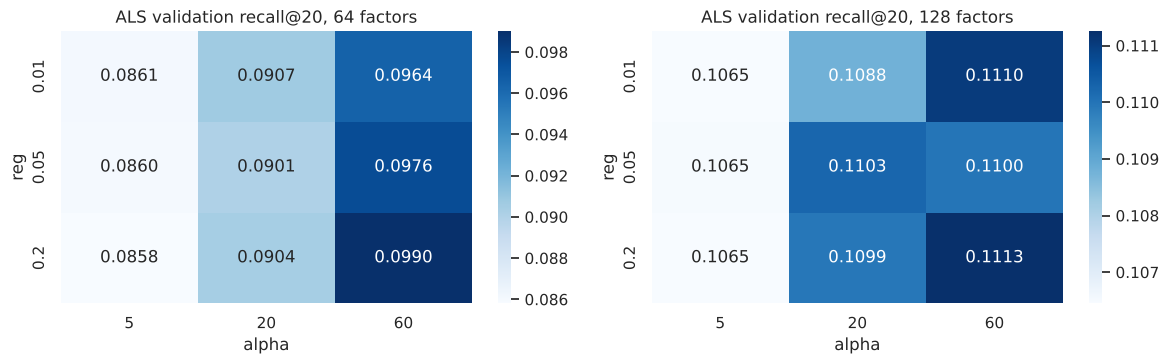

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for f, ax in zip([64, 128], axes):
    sns.heatmap(als_grid[als_grid.factors == f].pivot(index="reg", columns="alpha", values="recall@20"),
                annot=True, fmt=".4f", cmap="Blues", ax=ax)
    ax.set_title(f"ALS validation recall@20, {f} factors")
plt.tight_layout(); plt.savefig(FIG / "05_als_grid.png"); plt.show()

In [9]:
rows = []
for f, lr, it in [(64, 0.05, 150), (128, 0.1, 300), (128, 0.05, 300), (256, 0.1, 300)]:
    r = val_score(BPRRecommender(factors=f, lr=lr, iterations=it).fit(train))
    rows.append({"factors": f, "lr": lr, "iterations": it, "recall@20": r["recall@20"]})
bpr_grid = pd.DataFrame(rows).sort_values("recall@20", ascending=False)
bpr_grid

,factors,lr,iterations,recall@20
3,256,0.10,300,0.088161
1,128,0.10,300,0.086703
2,128,0.05,300,0.086152
0,64,0.05,150,0.078917


In [10]:
b = knn_grid.iloc[0]; a = als_grid.iloc[0]; p = bpr_grid.iloc[0]
best_params = {
    "knn": {"k": int(b.neighbours), "shrink": float(b.shrink)},
    "als": {"factors": int(a.factors), "reg": float(a.reg), "alpha": float(a.alpha)},
    "bpr": {"factors": int(p.factors), "lr": float(p.lr), "iterations": int(p.iterations)},
}
best_params

{'knn': {'k': 200, 'shrink': 10.0},
 'als': {'factors': 128, 'reg': 0.2, 'alpha': 60.0},
 'bpr': {'factors': 256, 'lr': 0.1, 'iterations': 300}}

## 3. Validation comparison

In [11]:
pop = PopularityRecommender().fit(train)
models = {
    "Random": RandomRecommender().fit(train),
    "Popularity": pop,
    "Content (text only)": ContentRecommender(blocks["text"]),
    "Content (tuned)": content,
    "Item-kNN": ItemKNN(**best_params["knn"]).fit(train),
    "ALS": ALSRecommender(**best_params["als"]).fit(train),
    "BPR": BPRRecommender(**best_params["bpr"]).fit(train),
}
res = {n: val_score(m, embeddings=E, popularity=tracks.popularity.values) for n, m in models.items()}
compare(res)

,recall@10,ndcg@10,hit@10,recall@20,ndcg@20,hit@20,coverage@10,avg_popularity@10,diversity@10
Random,0.0008,0.0004,0.0020,0.0008,0.0004,0.0020,0.5836,51.8746,0.5946
Popularity,0.0027,0.0017,0.0095,0.0061,0.0028,0.0175,0.0007,77.9472,0.3930
Content (text only),0.0116,0.0079,0.0350,0.0191,0.0105,0.0560,0.2922,53.7558,0.4388
Content (tuned),0.0398,0.0258,0.1240,0.0707,0.0371,0.2100,0.2809,55.7200,0.0373
Item-kNN,0.0678,0.0464,0.2160,0.1126,0.0630,0.3305,0.2731,59.4007,0.0880
ALS,0.0649,0.0453,0.1985,0.1113,0.0626,0.3205,0.2707,60.2345,0.0993
BPR,0.0516,0.0346,0.1680,0.0879,0.0478,0.2615,0.2886,58.0184,0.0817


On warm tracks, CF beats the tuned content model by about 1.6x: the simulated listeners' hidden
tastes, crossover habits and artist loyalty are only visible in co-listening. Item-kNN and ALS are
close, and BPR trails them. Content is weaker on warm tracks but, unlike CF, it can rank tracks
nobody has added yet, which notebook 06 measures. The tuned content model's low diversity is the
price of the heavy genre weight: its top 10 stays inside one scene.

In [12]:
short, short_users = short_playlists(train)
sv = short_users[np.isin(short_users, val_users)]
short_res = {n: evaluate(m, short, val, users=sv, ks=(10, 20)) for n, m in models.items() if n != "Random"}
print("Validation, only 3 seed tracks per playlist:")
compare(short_res)[["recall@10", "recall@20", "ndcg@10", "hit@10"]]

Validation, only 3 seed tracks per playlist:


,recall@10,recall@20,ndcg@10,hit@10
Popularity,0.0027,0.0061,0.0016,0.0090
Content (text only),0.0062,0.0120,0.0041,0.0191
Content (tuned),0.0282,0.0521,0.0188,0.0958
Item-kNN,0.0218,0.0419,0.0132,0.0656
ALS,0.0390,0.0725,0.0273,0.1313
BPR,0.0322,0.0564,0.0214,0.1027


With only three seeds, ALS holds up best: factorisation generalises from little evidence. Item-kNN
drops below the content model, because three tracks give it few neighbours to work with.

In [13]:
import json
(config.DATA_PROCESSED / "best_params.json").write_text(json.dumps({**best_params, "blocks": block_weights}, indent=2))
print("saved best_params.json")

saved best_params.json
